In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
!python smaparsing.py


sp500 1950-01-03 2026-10-09 19315 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq_comp 1971-02-05 2026-10-09 14037 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
nasdaq100 1985-10-01 2026-10-09 10336 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
ftse100 1984-01-03 2026-10-09 10805 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 5.0
nikkei 1965-01-05 2026-10-09 15183 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 11.0
dax 1987-12-30 2026-10-09 9807 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
cac40 1990-03-01 2026-10-09 9299 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 6.0
hang_seng 1986-12-31 2026-10-09 9816 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 7.0
shanghai 1997-07-02 2026-10-09 7089 // duplicates: 0 // NaN cells: 0 // longest gap (in days): 20.0


In [3]:
original_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/raw")

processed_data_path = Path("/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/data/processed")

In [4]:
PAYMENT = 250
INTEREST_RATE = 0.02
START_DATE = "1986-01-01"

DIV_YIELD = { 
    "sp500": 0.02, "nasdaq_comp": 0.01, "nasdaq100": 0.01, "ftse100": 0.04,
    "nikkei": 0.01, "dax": 0.0, "cac40": 0.03, "hang_seng": 0.03, "shanghai": 0.02,
}

STRATEGIES = {"DCA": None, "SMA50": "sma_50", "SMA100": "sma_100", "SMA200": "sma_200"}

In [5]:
import pandas as pd

def simulate(df, sma_col, dividend_yield, values=None):
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_col is not None:
        smas = df[sma_col].tolist()

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available
    start = df.index.get_loc(valid.index[0])

    cash = 0
    units = 0
    units_bought = 0
    total_spent = 0
    total_invested = 0
    n_buys = 0
    next_payment = dates[start] + pd.Timedelta(days=(7 - dates[start].weekday()) % 7)  # first Monday

    for i in range(start, len(df)):
        days = (dates[i] - dates[i - 1]).days
        cash *= (1 + INTEREST_RATE) ** (days / 365)
        units *= (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]:
            cash += PAYMENT
            total_invested += PAYMENT
            next_payment += pd.Timedelta(days=7)

        if sma_col is None:
            signal = True
        else:
            signal = closes[i - 1] <= smas[i - 1]

        if cash > 0 and signal:
            units += cash / closes[i]
            units_bought += cash / closes[i]
            total_spent += cash
            n_buys += 1
            cash = 0

        if values is not None:
            values.append(units * closes[i] + cash)

    final_value = units * closes[-1] + cash
    return {
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_spent / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
    }

In [6]:
df = pd.read_csv(processed_data_path / "sp500_processed.csv", index_col=0, parse_dates=True)
rows = []
for strategy, sma_col in STRATEGIES.items():
    rows.append(simulate(df, sma_col, DIV_YIELD["sp500"]))
pd.DataFrame(rows, index=STRATEGIES.keys())

,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
DCA,1986-01-02,2026-10-09,531750,9.136301e+06,1618.157192,1169.590225,830.866235,0.000000,2127
SMA50,1986-01-02,2026-10-09,531750,9.109816e+06,1613.176487,1166.103672,832.489615,750.447763,887
SMA100,1986-01-02,2026-10-09,531750,9.049612e+06,1601.854550,1157.656388,829.936712,6532.346903,722
SMA200,1986-01-02,2026-10-09,531750,9.014362e+06,1595.225495,1153.143833,834.571852,6532.346903,588


In [7]:
results_path = processed_data_path.parent.parent / "results"
results_path.mkdir(exist_ok=True)

rows = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True)
    for strategy, sma_col in STRATEGIES.items():
        row = {"index": name, "strategy": strategy}
        row.update(simulate(df, sma_col, DIV_YIELD[name]))
        rows.append(row)

results = pd.DataFrame(rows)

results.to_csv(results_path / "results.csv", index=False)

display(
    results.style.format({
        "total_invested": "{:,.0f}",
        "final_value": "{:,.0f}",
        "total_return_pct": "{:,.2f}",
        "units": "{:,.2f}",
        "avg_price": "{:,.2f}",
        "leftover_cash": "{:,.2f}",
    }, na_rep="NaN")
)

,index,strategy,start_date,end_date,total_invested,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys
0,sp500,DCA,1986-01-02,2026-10-09,"531,750","9,136,301","1,618.16","1,169.59",830.87,0.00,2127
1,sp500,SMA50,1986-01-02,2026-10-09,"531,750","9,109,816","1,613.18","1,166.10",832.49,750.45,887
2,sp500,SMA100,1986-01-02,2026-10-09,"531,750","9,049,612","1,601.85","1,157.66",829.94,"6,532.35",722
3,sp500,SMA200,1986-01-02,2026-10-09,"531,750","9,014,362","1,595.23","1,153.14",834.57,"6,532.35",588
4,nasdaq_comp,DCA,1986-01-02,2026-10-09,"531,750","14,958,705","2,713.11",546.61,"1,331.62",0.00,2127
5,nasdaq_comp,SMA50,1986-01-02,2026-10-09,"531,750","14,817,751","2,686.60",541.43,"1,343.39",750.45,914
6,nasdaq_comp,SMA100,1986-01-02,2026-10-09,"531,750","14,800,490","2,683.35",540.80,"1,347.03",750.45,770
7,nasdaq_comp,SMA200,1986-01-02,2026-10-09,"531,750","14,880,974","2,698.49",543.53,"1,330.65","6,532.35",645
8,nasdaq100,DCA,1986-07-16,2026-10-09,"524,750","28,981,730","5,422.96",938.43,775.65,0.00,2099
9,nasdaq100,SMA50,1986-07-16,2026-10-09,"524,750","28,705,376","5,370.30",929.46,782.81,750.45,920


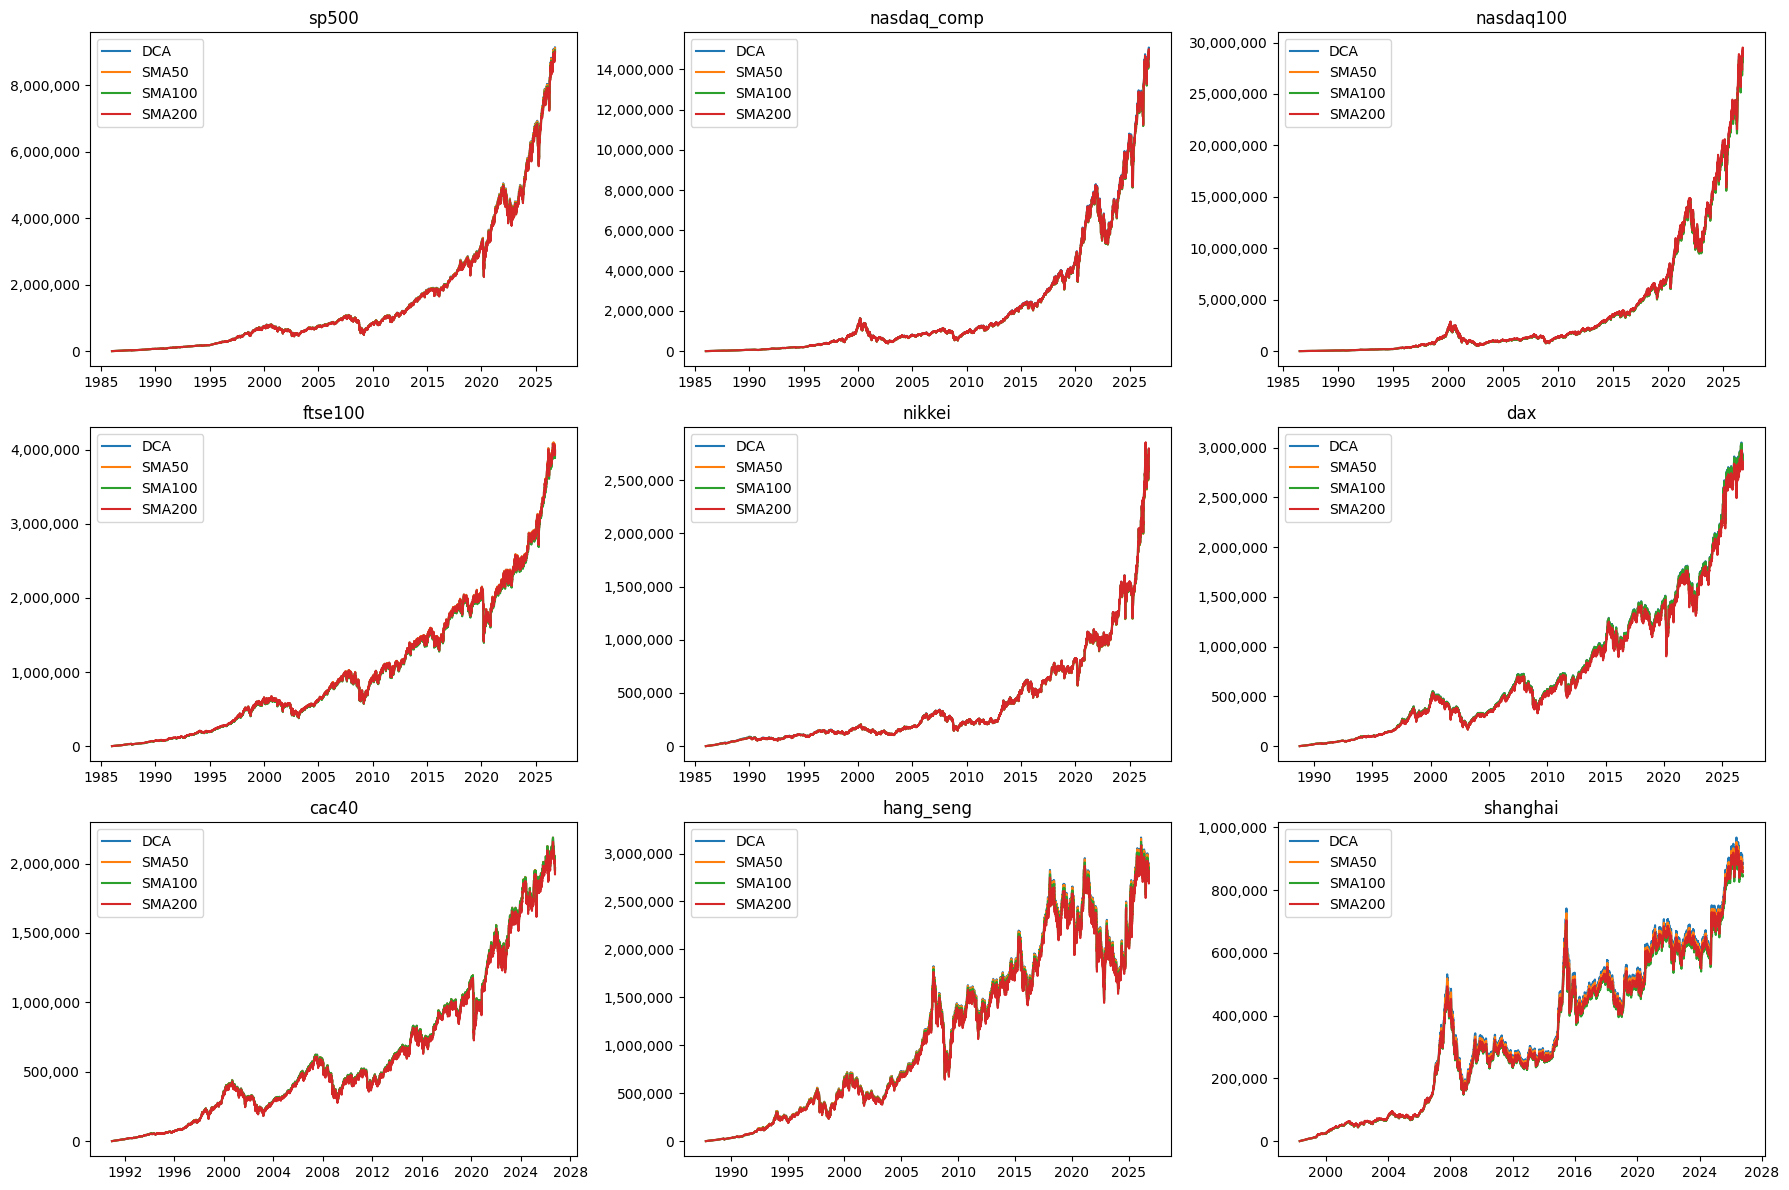

In [12]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, name in zip(axes.flatten(), DIV_YIELD):
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        ax.plot(df.index[-len(values):], values, label=strategy)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

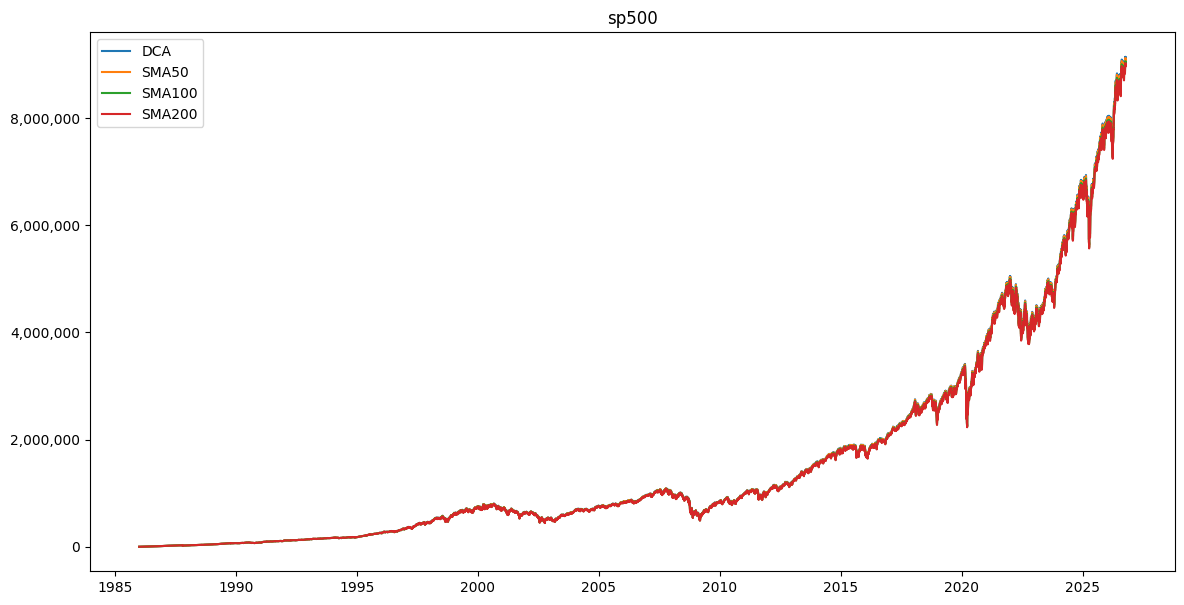

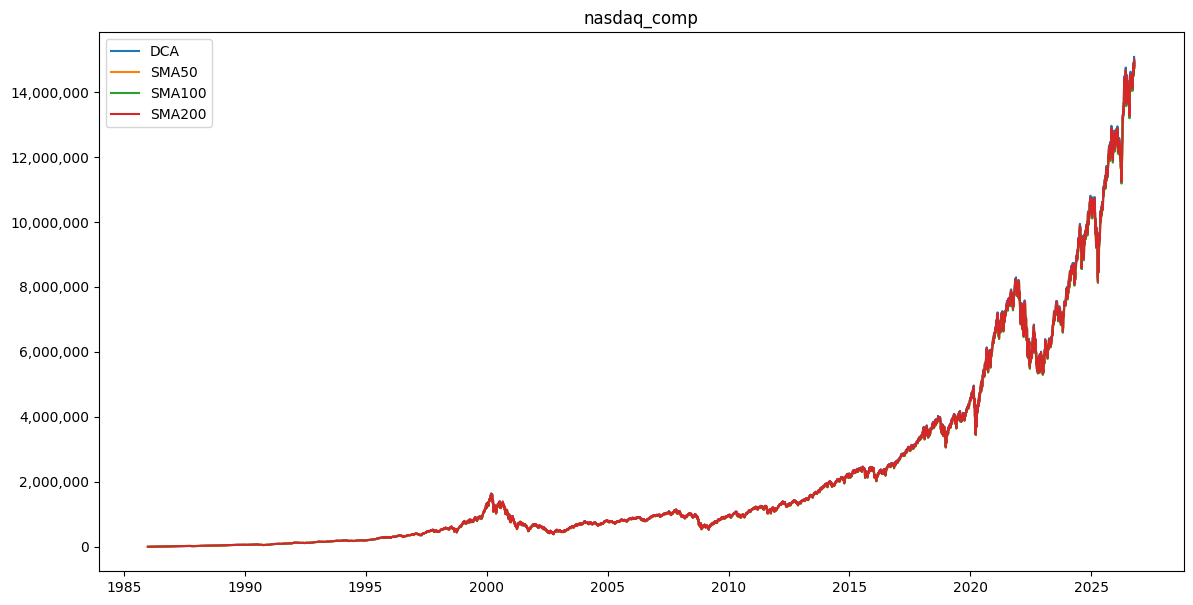

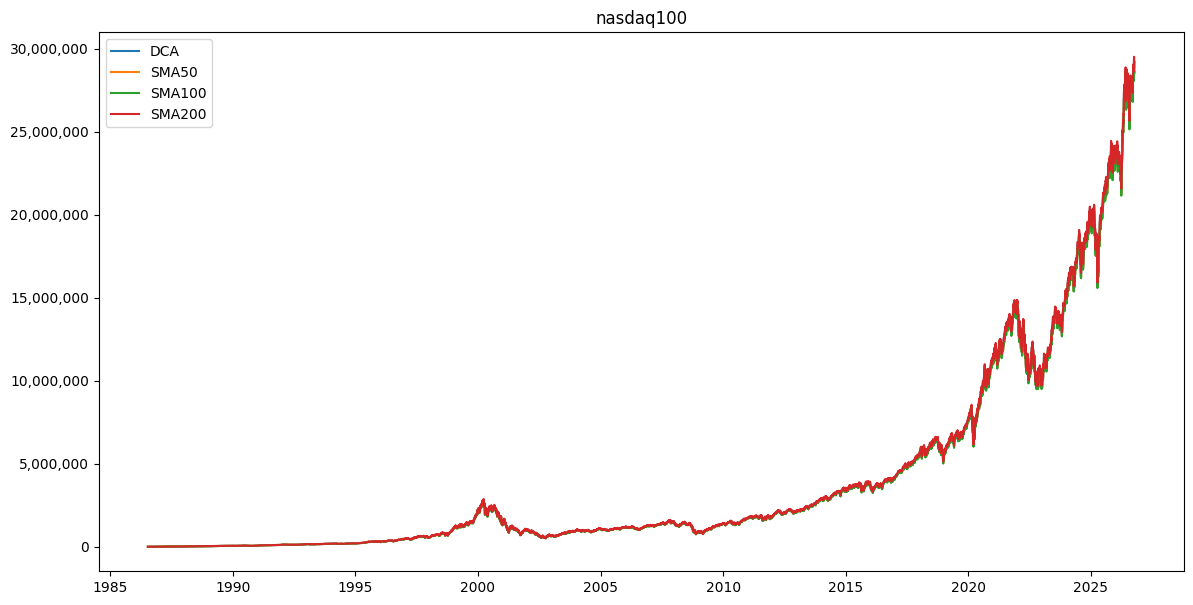

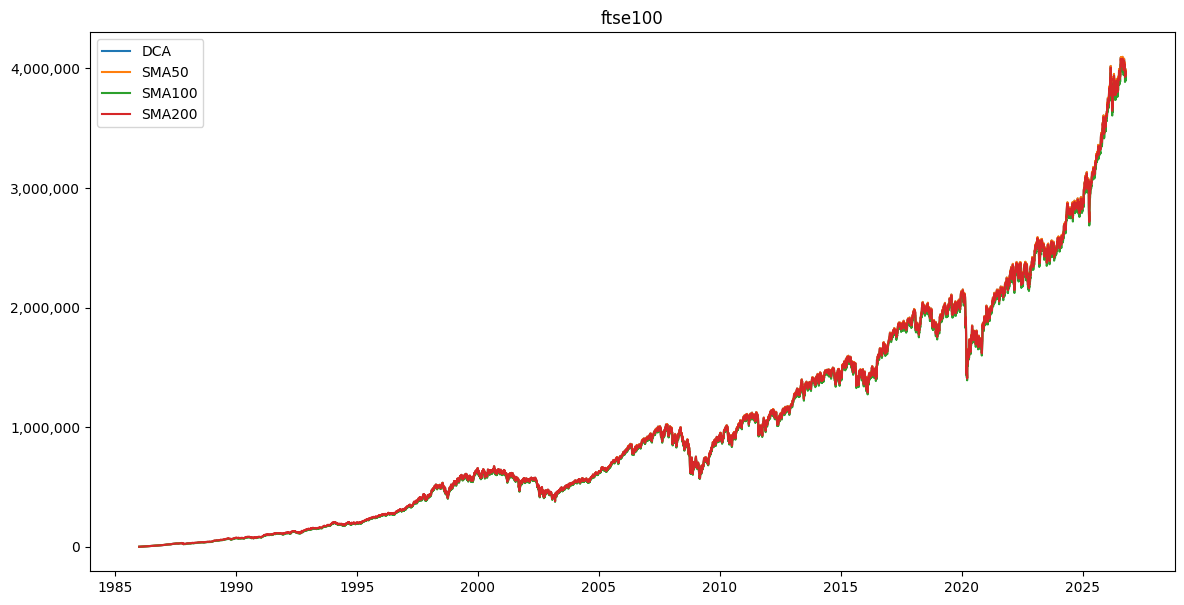

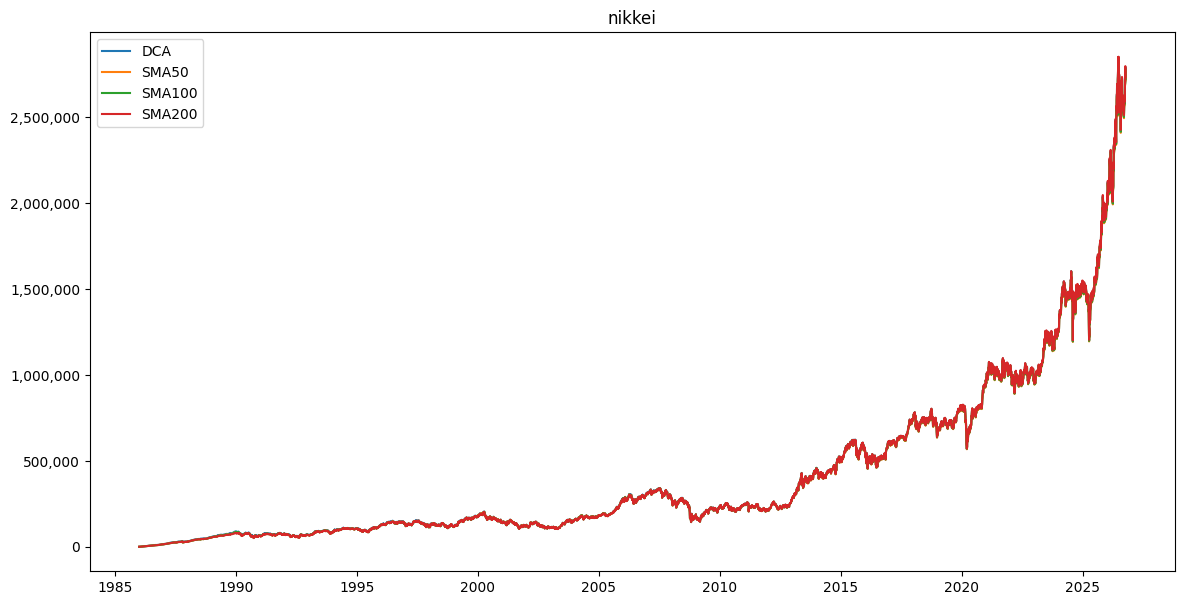

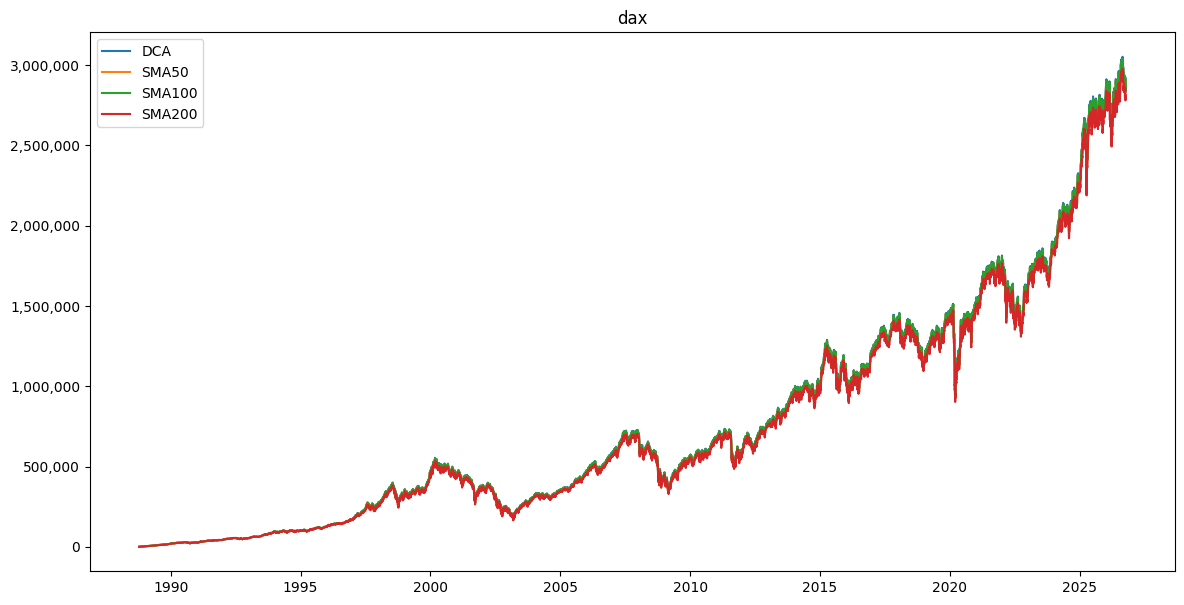

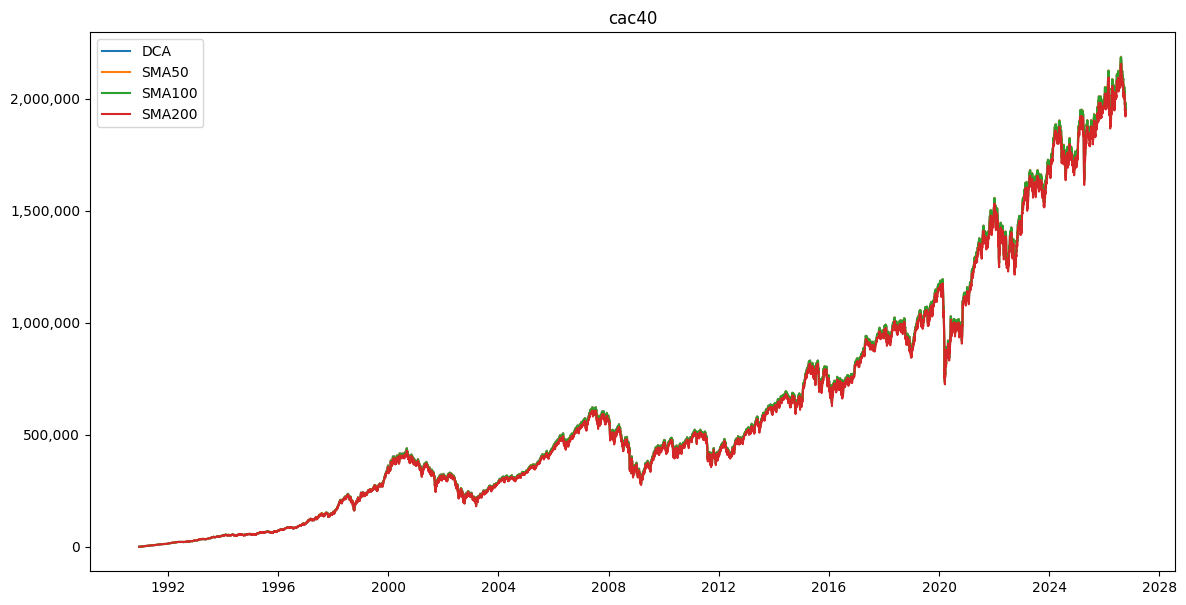

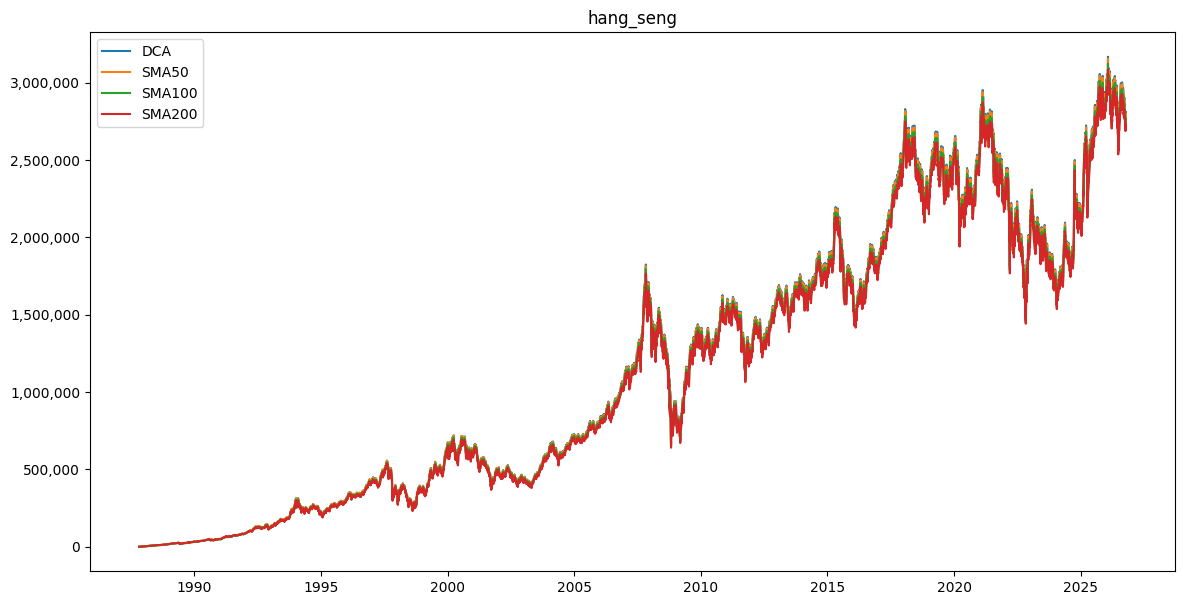

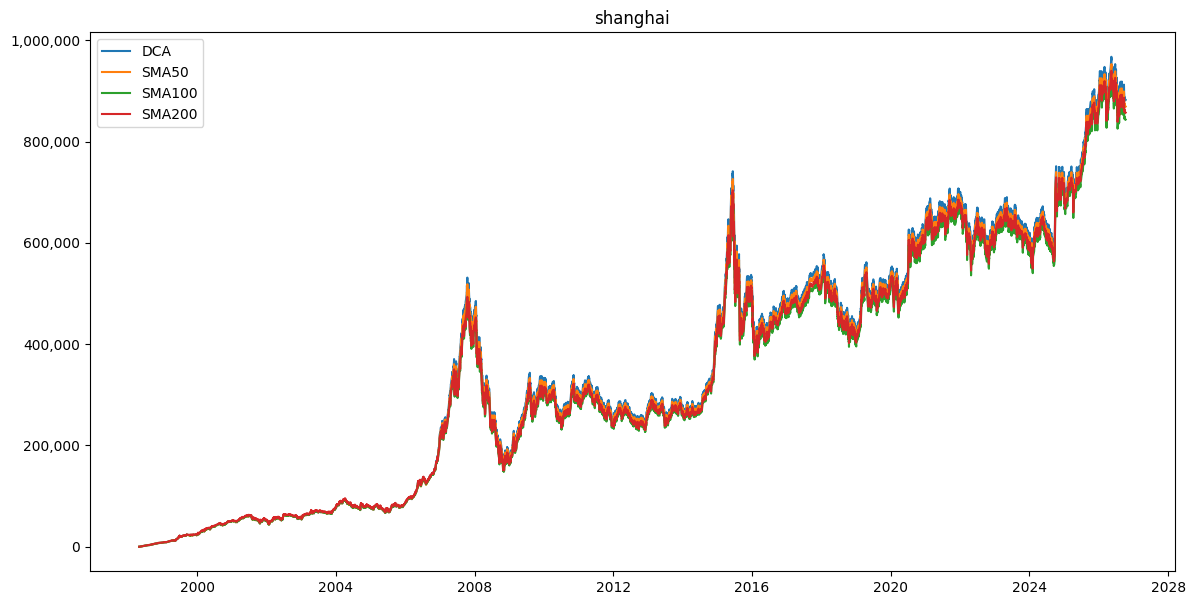

In [14]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    fig, ax = plt.subplots(figsize=(14, 7))
    for strategy, sma_col in STRATEGIES.items():
        values = []
        simulate(df, sma_col, DIV_YIELD[name], values)
        series = pd.Series(values, index=df.index[-len(values):])["1986-01-01":]
        ax.plot(series.index, series.values, label=strategy)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
    ax.legend()
    plt.show()

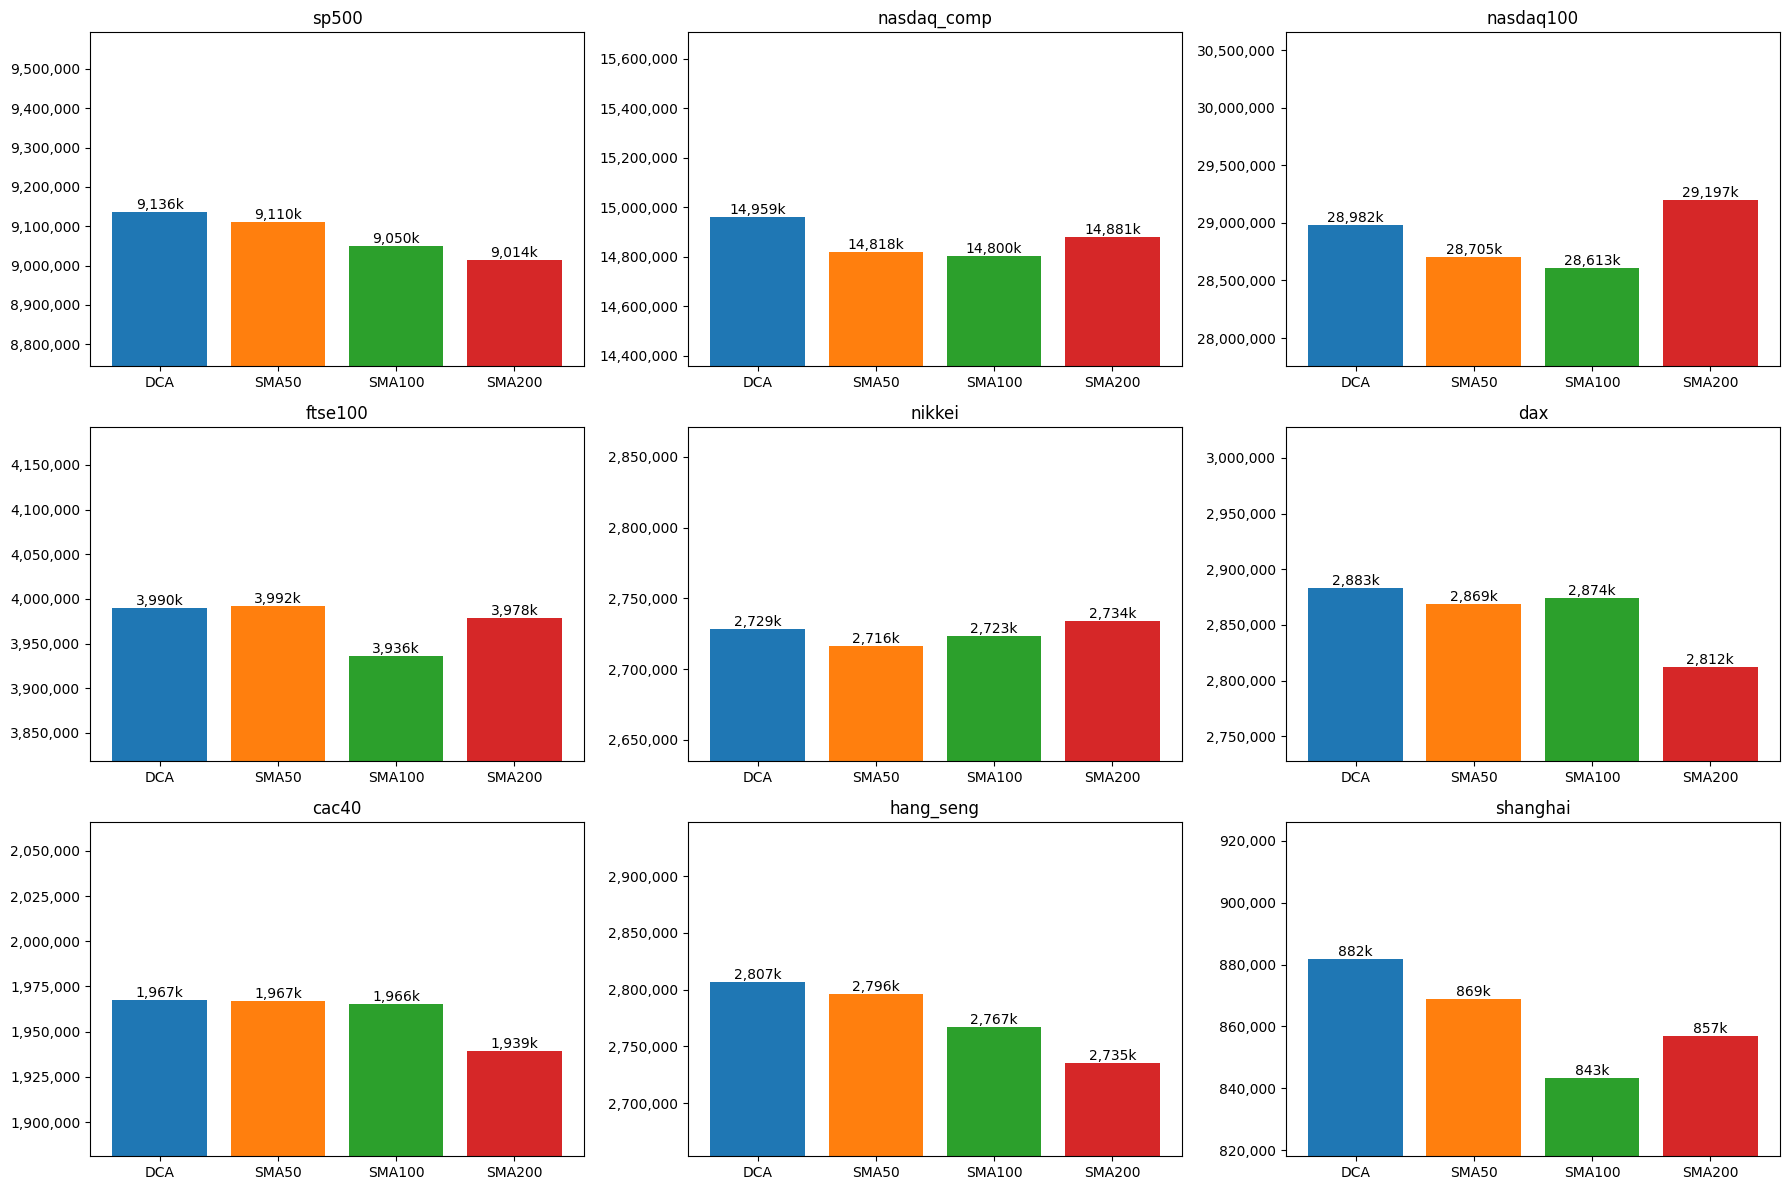

In [15]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

fig, axes = plt.subplots(3, 3, figsize=(18, 12))
for ax, name in zip(axes.flatten(), DIV_YIELD):
    df = pd.read_csv(processed_data_path / f"{name}_processed.csv", index_col=0, parse_dates=True).dropna(subset=["Close"])
    final_values = []
    labels = []
    for strategy, sma_col in STRATEGIES.items():
        result = simulate(df, sma_col, DIV_YIELD[name])
        final_values.append(result["final_value"])
        labels.append(f"{result['final_value'] / 1000:,.0f}k")
    bars = ax.bar(list(STRATEGIES), final_values, color=colors)
    ax.bar_label(bars, labels=labels)
    ax.set_ylim(bottom=min(final_values) * 0.97)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_title(name)
plt.tight_layout()
plt.show()